In [1]:
import os
import pandas as pd
import wfdb   # Permite leer señales fisiológicas en formato PhysioNet
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.collections import LineCollection
from matplotlib.ticker import AutoMinorLocator
from PIL import Image
import seaborn as sns
from collections import Counter
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold
from tqdm import tqdm

# **GENERACIÓN DE IMÁGENES SINTÉTICAS**

Para ampliar la cantidad de imágenes disponibles para el entrenamiento de los modelos, y dado que existen pocos datasets públicos de imágenes de ECG (especialmente con un formato similar al de las imágenes de interés en este trabajo), se decidió generar imágenes sintéticas a partir de señales de ECG. El objetivo es que las imágenes generadas reproduzcan, lo mejor posible, el formato y el layout de la imagen de referencia mostrada a continuación.

In [2]:
# Imagen de referencia
ref_path = r"C:\Users\Victoria\Desktop\Referencia.jpg"

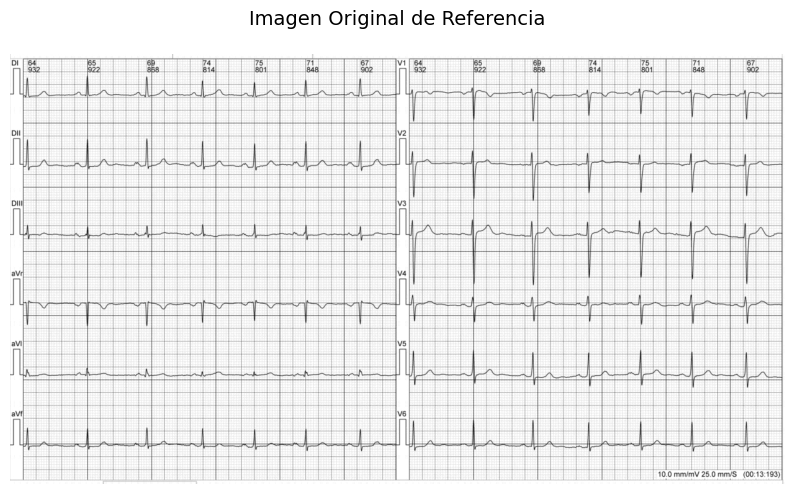

In [3]:
img_ref = Image.open(ref_path)

plt.figure(figsize=(10, 6))
plt.imshow(img_ref, cmap='gray')
plt.title("Imagen Original de Referencia", fontsize=14, y=1.05)
plt.axis("off")
plt.show()

A partir de una imagen de referencia del ICBA, se identificaron las características a replicar:

- **Formato:** hoja apaisada con 12 derivaciones en 2 columnas de 6 filas (DI a aVF a la izquierda, V1 a V6 a la derecha), ambas del mismo ancho.
- **Grilla:** fondo blanco con grilla gris clara, continua dentro de cada columna y delimitada por un borde más grueso. Tres niveles de línea (1 mm, 5 mm y 25 mm), con cuadrados sin deformar.
- **Pulso de calibración:** antes de cada derivación, sobre una franja blanca, de 10 mm de alto (1 mV) y 2,5 mm de ancho (0,1 s), con el mismo trazo que la señal.
- **Señal:** trazo fino, dibujado sobre la grilla a continuación del pulso, con separación uniforme entre derivaciones (puede haber superposición si la amplitud es elevada).
- **Etiquetas y texto:** nombre de cada derivación sobre su pulso y escala de visualización (10,0 mm/mV y 25,0 mm/s) en la esquina inferior derecha.
- **Sin elementos de matplotlib:** sin ejes ni marcas numéricas, para que la imagen se vea como un ECG real.


La generación de las imágenes se organiza de manera modular, separando la construcción del fondo, los elementos de referencia y el trazado de las señales.

Antes de construir la imagen, se definieron funciones auxiliares para trabajar con distintas unidades de medida. En particular, el diseño del ECG se plantea en unidades físicas de milímetros, con el objetivo de conservar la escala propia del papel de electrocardiograma. Esta decisión resulta importante porque permite que las distancias espaciales del trazado mantengan una correspondencia directa con las convenciones clínicas habituales, como la grilla de 1 mm, 5 mm y 25 mm.

Dado que Matplotlib define el tamaño de las figuras en pulgadas, se utiliza una función de conversión de milímetros a pulgadas para establecer el tamaño físico de la imagen al momento del renderizado. A su vez, la resolución final en píxeles queda determinada por el parámetro DPI (dots per inch). Para una resolución de 300 dpi, 1 mm se representa aproximadamente con 11,8 píxeles, es decir, cerca de 12 píxeles por milímetro.

In [4]:
def px_to_mm(px, dpi=300):
    return px * 25.4 / dpi


def mm_to_inch(mm):
    return mm / 25.4

**CONSTRUCCIÓN DE LA GRILLA BASE**

En primer lugar, la función **plot_grid()** se encarga de generar la hoja base sobre la cual se dibujan todos los elementos del ECG. Esta función define la geometría completa de la imagen en unidades físicas (milímetros), a partir de la cantidad de cuadrados grandes de la grilla en sentido horizontal y vertical.

A partir de estos parámetros, se calcula el tamaño total de la hoja, incluyendo los márgenes exteriores, la zona reservada para el pulso de calibración a la izquierda de cada columna y la separación entre columnas. Con esta información, se crea una figura de Matplotlib con fondo blanco y un sistema de coordenadas expresado en milímetros, lo que permite posicionar todos los elementos gráficos de manera independiente de la resolución en píxeles.

La grilla se construye superponiendo tres niveles visuales: líneas finas cada 1 mm, líneas intermedias cada 5 mm y líneas más destacadas cada 25 mm. Además, se incorpora un borde perimetral que delimita claramente la región útil de la grilla respecto del fondo blanco, reproduciendo la apariencia de las hojas clínicas de ECG. Finalmente, se añade un texto técnico en la esquina inferior derecha que indica las escalas de amplitud y tiempo utilizadas.

Como salida, la función devuelve la figura, el eje de dibujo y un diccionario denominado layout_info, que contiene toda la información geométrica relevante (dimensiones, márgenes y posiciones). Este diccionario resulta fundamental para garantizar la correcta alineación de los elementos en las etapas posteriores.

In [5]:
def plot_grid(
    dpi=300,                     # Resolución de la figura en puntos por pulgada.
    margin_x_mm=1,               # Margenes laterales.
    margin_y_mm=1,               # Margen superior e inferior.
    pulse_zone_mm=5,             # Ancho de la zona a la izquierda de cada grilla donde se dibuja el pulso de calibración.
    inter_col_gap_mm=0,          # Separación extra entre columnas (en este caso el pulso ya ocupa ese espacio).
    grid_big_boxes_w=29,         # Cantidad de cuadrados de ancho
    grid_big_boxes_h=33,         # Cantidad de cuadrados de alto
):

    # Parámetros de texto
    tech_fontsize=7
    tech_color="#212121"
    tech_text="10.0 mm/mV   25.0 mm/S"

    # Parámetros de grid
    small_grid_color="#d6d6d6"
    medium_grid_color="#b5b5b5"
    large_grid_color="#757575"
    lw_small=0.35
    lw_medium=0.55
    lw_large=0.9

    # Tamaño de grid
    grid_w = grid_big_boxes_w * 5   # 145 mm
    grid_h = grid_big_boxes_h * 5   # 165 mm
    col_w = pulse_zone_mm + grid_w

    # Tamaño total hoja
    width_mm = 2 * margin_x_mm + 2 * col_w + inter_col_gap_mm
    height_mm = 2 * margin_y_mm + grid_h

    # Crear la figura
    fig = plt.figure(
        figsize=(mm_to_inch(width_mm), mm_to_inch(height_mm)),
        dpi=dpi,
        facecolor="white"
    )
    ax = plt.axes([0, 0, 1, 1], facecolor="white")
    ax.set_xlim(0, width_mm)
    ax.set_ylim(0, height_mm)
    ax.set_aspect("equal")     # Asegura que la escala de ambos ejes sea la misma
    ax.axis("off")

    # Dibujar grilla
    col1_x0 = margin_x_mm
    col2_x0 = margin_x_mm + col_w + inter_col_gap_mm
    col_y0 = margin_y_mm
    grid1_x0 = col1_x0 + pulse_zone_mm
    grid2_x0 = col2_x0 + pulse_zone_mm

    # Funciones auxiliares para construir segmentos de línea.
    def make_vlines(xs, y0, y1):
        segs = np.empty((len(xs), 2, 2))
        segs[:, 0, 0] = xs;  segs[:, 0, 1] = y0
        segs[:, 1, 0] = xs;  segs[:, 1, 1] = y1
        return segs

    def make_hlines(ys, x0, x1):
        segs = np.empty((len(ys), 2, 2))
        segs[:, 0, 0] = x0;  segs[:, 0, 1] = ys
        segs[:, 1, 0] = x1;  segs[:, 1, 1] = ys
        return segs

    def draw_grid(x0, y0, w, h):
        # Fondo blanco -----------------
        ax.add_patch(Rectangle(
            (x0, y0), w, h,
            facecolor="white",
            edgecolor="none",
            zorder=0
        ))

        # Grilla de 1 mm -----------------
        segs = np.vstack([
            make_vlines(np.arange(x0, x0 + w + 1e-9, 1), y0, y0 + h),
            make_hlines(np.arange(y0, y0 + h + 1e-9, 1), x0, x0 + w),
        ])
        ax.add_collection(LineCollection(segs, colors=small_grid_color, linewidths=lw_small, zorder=1))

        # Grilla de 5 mm -----------------
        segs = np.vstack([
            make_vlines(np.arange(x0, x0 + w + 1e-9, 5), y0, y0 + h),
            make_hlines(np.arange(y0, y0 + h + 1e-9, 5), x0, x0 + w),
        ])
        ax.add_collection(LineCollection(segs, colors=medium_grid_color, linewidths=lw_medium, zorder=2))

        # Grilla de 25 mm -----------------
        segs = np.vstack([
            make_vlines(np.arange(x0, x0 + w + 1e-9, 25), y0, y0 + h),
            make_hlines(np.arange(y0 + h, y0 - 1e-9, -25), x0, x0 + w),  # Horizontales: arrancan desde el borde superior
        ])
        ax.add_collection(LineCollection(segs, colors=large_grid_color, linewidths=lw_large, zorder=3))

        # Borde del grid -----------------
        ax.add_patch(Rectangle(
            (x0, y0), w, h,
            facecolor="none",
            edgecolor=large_grid_color,
            linewidth=lw_large,
            zorder=4
        ))

    draw_grid(grid1_x0, col_y0, grid_w, grid_h)
    draw_grid(grid2_x0, col_y0, grid_w, grid_h)

    # Texto técnico
    offset_x = -1
    offset_y = 1
    tech_x = grid2_x0 + grid_w + offset_x
    tech_y = col_y0 + offset_y

    ax.text(
        tech_x, tech_y, tech_text,
        fontsize=tech_fontsize,
        family="sans-serif",
        color=tech_color,
        ha="right",
        va="bottom",
        zorder=10,
        bbox=dict(facecolor="white", edgecolor="none", pad=2)
    )

    layout_info = {
        "width_mm": width_mm,
        "height_mm": height_mm,
        "margin_x_mm": margin_x_mm,
        "margin_y_mm": margin_y_mm,
        "pulse_zone_mm": pulse_zone_mm,
        "inter_col_gap_mm": inter_col_gap_mm,
        "grid_w": grid_w,
        "grid_h": grid_h,
        "col_w": col_w,
        "col1_x0": col1_x0,
        "col2_x0": col2_x0,
        "grid1_x0": grid1_x0,
        "grid2_x0": grid2_x0,
        "col_y0": col_y0,
        "lw_large": lw_large,
        "large_grid_color": large_grid_color,
    }

    return fig, ax, layout_info

**GRÁFICO DE PULSOS DE CALIBRACIÓN Y ETIQUETAS**

La función **plot_pulse()** se encarga de dibujar los pulsos de calibración de cada derivación sobre la hoja de ECG, junto con su etiqueta correspondiente. Para ubicar correctamente cada pulso dentro de la figura, la función utiliza el diccionario layout_info que devuelve plot_grid(), de modo que las posiciones de los pulsos se calculan en milímetros y son independientes del tamaño físico de la hoja o de la resolución de la imagen. Esto asegura que los pulsos se mantengan siempre en la posición correcta respecto a la grilla y los márgenes definidos.

Primero, la función obtiene de layout_info las coordenadas y dimensiones necesarias de cada columna y de la grilla, como la posición vertical inicial (col_y0), la altura del grid (grid_h) y las posiciones horizontales de cada columna (col1_x0, col2_x0) y de las grillas internas (grid1_x0, grid2_x0). A continuación, divide la altura de cada columna entre seis filas, correspondientes a las seis derivaciones por columna, y calcula la altura de la línea de base de cada pulso. El 0.5 que aparece al calcular la línea de base sirve para centrar verticalmente el pulso dentro de la fila correspondiente, de modo que el pulso no quede alineado con el borde superior o inferior de la fila sino centrado.

Luego, la función recorre ambas columnas y todas las derivaciones, calculando para cada pulso sus posiciones horizontales y verticales a partir de la línea de base. El parámetro pulse_width_mm determina cuánto se extiende horizontalmente la porción alta del pulso, mientras que pulse_height_mm define la altura vertical máxima. Los parámetros left_stub_mm y right_stub_mm controlan la extensión horizontal antes y después del pulso, representando los tramos en los que la señal permanece en cero. De esta manera, el pulso completo se compone de un tramo horizontal inicial en cero, una subida vertical, una meseta horizontal en el valor máximo, una bajada vertical y un tramo horizontal final de retorno a cero.

Finalmente, la función dibuja el nombre de cada derivación encima de la parte alta del pulso, de manera que siempre esté visible y centrado respecto a la meseta del pulso. Para ello, se calcula la posición horizontal como el punto medio de la meseta del pulso y la posición vertical ligeramente por encima del valor máximo del pulso, usando un pequeño margen para que el texto no quede pegado a la línea. De esta forma, las etiquetas se mantienen alineadas correctamente con cada pulso sin importar su altura, ancho o la ubicación dentro de la columna.

In [6]:
def plot_pulse(
    ax,
    layout_info,
    lead_names,              # Nombre de derivaciones
    pulse_height_mm=10,      # Alto del pulso
    pulse_width_mm=2.5,      # Ancho del pulso
    left_stub_mm=1.25,       # Extensión horizontal antes del pulso
    right_stub_mm=1.25       # Extensión horizontal después del pulso
):

    # Parámetros del pulso
    pulse_linewidth=0.9     # Grosor de línea
    pulse_color="#5a5a5a"

    # Parámetros de etiqueta
    label_fontsize=7.8
    label_color="#212121"

    # Extraemos coordenadas y dimensiones de layout_info
    col_y0 = layout_info["col_y0"]
    grid_h = layout_info["grid_h"]
    col1_x0 = layout_info["col1_x0"]
    col2_x0 = layout_info["col2_x0"]
    grid1_x0 = layout_info["grid1_x0"]
    grid2_x0 = layout_info["grid2_x0"]

    # Calcular la altura de la línea de base del pulso para cada derivación.
    row_h = grid_h / 6.0
    baselines = [col_y0 + grid_h - (i + 0.5) * row_h for i in range(6)]

    # Graficar los pulsos
    pulse_info = []
    columns = [(0, col1_x0, grid1_x0),(1, col2_x0, grid2_x0)]

    for col_idx, col_x0, grid_x0 in columns:
        for i in range(6):
            lead_idx = i if col_idx == 0 else i + 6
            baseline_y = baselines[i]

            # El borde del grid queda al final del tramo horizontal inferior
            x_after = grid_x0
            x_down = x_after - right_stub_mm
            x_top_end = x_down
            x_up = x_down - pulse_width_mm
            x_start = x_up

            y_base = baseline_y
            y_top = baseline_y + pulse_height_mm

            # Tramo horizontal antes del pulso ----------------------------
            if left_stub_mm > 0:
                ax.plot(
                    [x_start - left_stub_mm, x_start], [y_base, y_base],
                    color=pulse_color, linewidth=pulse_linewidth, zorder=20
                )

            # Subida vertical ---------------------------------------------
            ax.plot(
                [x_up, x_up], [y_base, y_top],
                color=pulse_color, linewidth=pulse_linewidth, zorder=20
            )

            # Meseta ------------------------------------------------------
            ax.plot(
                [x_up, x_top_end], [y_top, y_top],
                color=pulse_color, linewidth=pulse_linewidth, zorder=20
            )

            # Bajada vertical --------------------------------------------
            ax.plot(
                [x_down, x_down], [y_top, y_base],
                color=pulse_color, linewidth=pulse_linewidth, zorder=20
            )

            # Tramo horizontal después del pulso -------------------------
            if right_stub_mm > 0:
                ax.plot(
                    [x_down, x_after], [y_base, y_base],
                    color=pulse_color, linewidth=pulse_linewidth, zorder=20
                )

            # Etiqueta de derivación -------------------------------------
            label_x = x_up + pulse_width_mm / 2
            label_y = y_top + pulse_height_mm * 0.05


            ax.text(
                label_x,
                label_y,
                lead_names[lead_idx],
                fontsize=label_fontsize,
                family="sans-serif",
                color=label_color,
                ha="center",
                va="bottom",
                zorder=21
            )

**GRÁFICO DE SEÑALES**

La función **plot_signal()** se encarga de representar las doce derivaciones del ECG sobre la grilla. La señal de entrada se organiza en una matriz de dimensión (12, N), donde cada fila corresponde a una derivación completa, lo que facilita su recorrido y procesamiento individual.

A partir de la información geométrica contenida en layout_info, la función determina la ubicación de cada señal dentro de la hoja, asignando las primeras seis derivaciones a la columna izquierda y las seis restantes a la columna derecha. Asimismo, calcula la duración temporal que puede representarse en cada columna en función del ancho físico de la grilla y la escala temporal utilizada (mm/s). Con esta duración y la frecuencia de muestreo, se determina la cantidad de muestras necesarias para completar cada columna. Si una señal contiene más muestras que las requeridas, se recorta al intervalo correspondiente. El eje temporal se define a partir de la duración máxima representable en la grilla. Sin embargo, si es más corta, se representa únicamente el segmento existente, sin completar artificialmente el resto del eje temporal.

Finalmente, cada muestra de la señal se transforma a coordenadas físicas expresadas en milímetros. La componente horizontal se obtiene a partir del tiempo, utilizando la escala temporal definida en mm/s, mientras que la componente vertical se calcula a partir de la amplitud de la señal, empleando la escala de amplitud expresada en mm/mV. Con estas coordenadas, la función grafica cada derivación sobre la grilla, obteniendo una representación sintética del ECG coherente.

In [7]:
def plot_signal(
    ax,
    layout_info,
    ecg_data,
    sampling_rate,
    signal_color="#5a5a5a",
    signal_linewidth=0.9,
    amplitude_scale=10,   # mm/mV
    time_scale=25         # mm/s
):

    ecg_data = np.asarray(ecg_data)

    if ecg_data.shape[0] != 12:
        raise ValueError("ecg_data debe tener shape (12, N)")

    grid_w = layout_info["grid_w"]
    grid_h = layout_info["grid_h"]
    grid1_x0 = layout_info["grid1_x0"]
    grid2_x0 = layout_info["grid2_x0"]
    col_y0 = layout_info["col_y0"]

    # Calcular la duración temporal de la señal
    seconds_per_column = grid_w / time_scale
    n_samples_needed = int(round(seconds_per_column * sampling_rate))

    # Calcular la altura de la línea de base de la señal para cada derivación
    row_h = grid_h / 6.0
    baselines = [col_y0 + grid_h - (i + 0.5) * row_h for i in range(6)]

    for lead_idx in range(12):
        col_idx = 0 if lead_idx < 6 else 1                        # Columnas
        row_idx = lead_idx if lead_idx < 6 else lead_idx - 6      # Filas

        x0 = grid1_x0 if col_idx == 0 else grid2_x0
        baseline_y = baselines[row_idx]

        lead_signal = ecg_data[lead_idx]

        # Ajustar longitud de la señal a la cantidad de muestras que entran en una columna
        if len(lead_signal) > n_samples_needed:
            lead_signal = lead_signal[:n_samples_needed]

        # Eje temporal en segundos
        t_full = np.arange(n_samples_needed) / sampling_rate

        # Usar solo la parte donde hay señal
        n = len(lead_signal)
        t = t_full[:n]

        # Conversión a coordenadas físicas en mm
        x_mm = x0 + time_scale * t
        y_mm = baseline_y + amplitude_scale * lead_signal

        ax.plot(
            x_mm, y_mm,
            color=signal_color,
            linewidth=signal_linewidth,
            zorder=30
        )

Como la salida obtenida a partir de estas funciones corresponde a una figura de Matplotlib, resulta necesario convertirla a un formato de imagen que pueda manipularse más fácilmente dentro del pipeline. Para ello, se define la función fig_to_array(), cuya finalidad es transformar la figura ya renderizada en un arreglo de NumPy que represente la imagen en formato RGB.

En primer lugar, la función fuerza el renderizado completo de la figura mediante fig.canvas.draw(), asegurando que todos los elementos gráficos previamente definidos (grilla, pulsos, labels y señales) queden efectivamente dibujados en memoria. Luego, obtiene el tamaño del canvas en píxeles y accede al buffer de imagen generado por Matplotlib en formato RGBA. A partir de ese buffer, construye un arreglo de NumPy con dimensiones (alto, ancho, n° de canales).

Por último, la función descarta el canal alpha (transparencia) y conserva únicamente los tres canales RGB, obteniendo así una matriz de dimensiones (alto, ancho, 3). De esta manera, la figura deja de ser un objeto gráfico de Matplotlib y pasa a representarse como una imagen digital convencional, lista para ser visualizada y guardada.

In [8]:
def fig_to_array(fig):
    fig.canvas.draw()
    w, h = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
    buf = buf.reshape(h, w, 4)
    img = buf[:, :, :3].copy()   # Eliminar canal alpha (transparencia)
    return img

Finalmente, función **generate_image()** integra todos los módulos anteriores en un único flujo de generación. En primer lugar, crea la grilla base mediante plot_grid(), obteniendo tanto la figura como la información geométrica del layout. A continuación, dibuja los pulsos de calibración con plot_pulse() y posteriormente las señales de ECG con plot_signal(), asegurando que todos los elementos queden correctamente alineados. Por último, la figura completa se convierte a una imagen RGB utilizando fig_to_array() y se libera la memoria asociada a la figura.

In [9]:
def generate_image(
    ecg_data,
    lead_names,
    sampling_rate=500,
    dpi=200,
    margin_x_mm=1,
    margin_y_mm=1,
    save_path=None       
):

    # Generar grilla base con márgenes variables
    fig, ax, layout_info = plot_grid(
        dpi=dpi,
        margin_x_mm=margin_x_mm,
        margin_y_mm=margin_y_mm
    )

    # Dibujar pulsos de calibración
    plot_pulse(ax, layout_info, lead_names=lead_names)

    # Dibujar señales ECG
    plot_signal(ax, layout_info, ecg_data, sampling_rate=sampling_rate)

    if save_path is not None:
        # Guardar imagen en disco
        fig.savefig(save_path, format="jpg", dpi=dpi)
        plt.close(fig)
    else:
        # Convertir la figura a imagen RGB
        img = fig_to_array(fig)
        plt.close(fig)
        return img

A continuación, se muestra una imagen generada con esta función utilizando una de las señales del dataset.

In [10]:
signal_path = r"C:\Users\Victoria\Desktop\Datos Señales Filtered\000005"

# Cargar señal
signal, metadata = wfdb.rdsamp(signal_path)
signal_to_plot = signal.T

# Frecuencia de muestreo
sampling_rate = metadata['fs']

# Derivaciones
lead_names = ["DI","DII","DIII","aVr","aVl","aVf","V1","V2","V3","V4","V5","V6"] # Mismo orden que la metadata

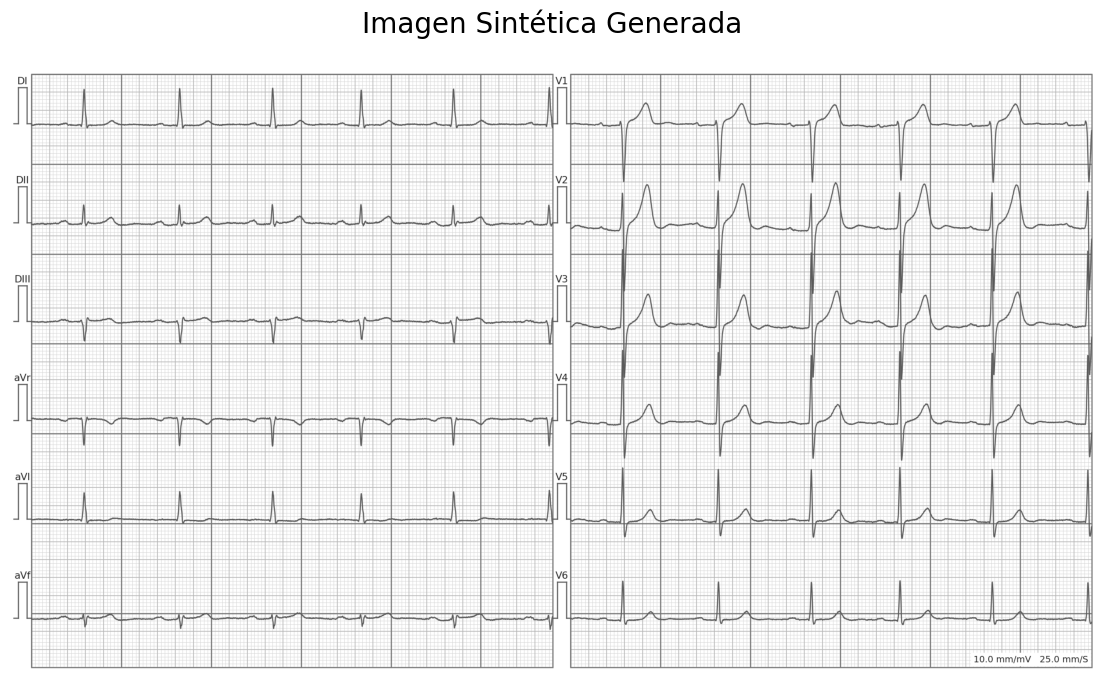

In [11]:
img_syn = generate_image(
    ecg_data=signal_to_plot,
    lead_names=lead_names,
    sampling_rate=sampling_rate,
)

plt.figure(figsize=(14, 8))
plt.imshow(img_syn)
plt.title("Imagen Sintética Generada", y=1.05, fontsize=20)
plt.axis("off")
plt.show()

Para facilitar la comparación visual con la imagen de referencia, se grafican ambas imágenes lado a lado en un subplot. Cabe destacar que ambas imágenes corresponden a registros distintos.

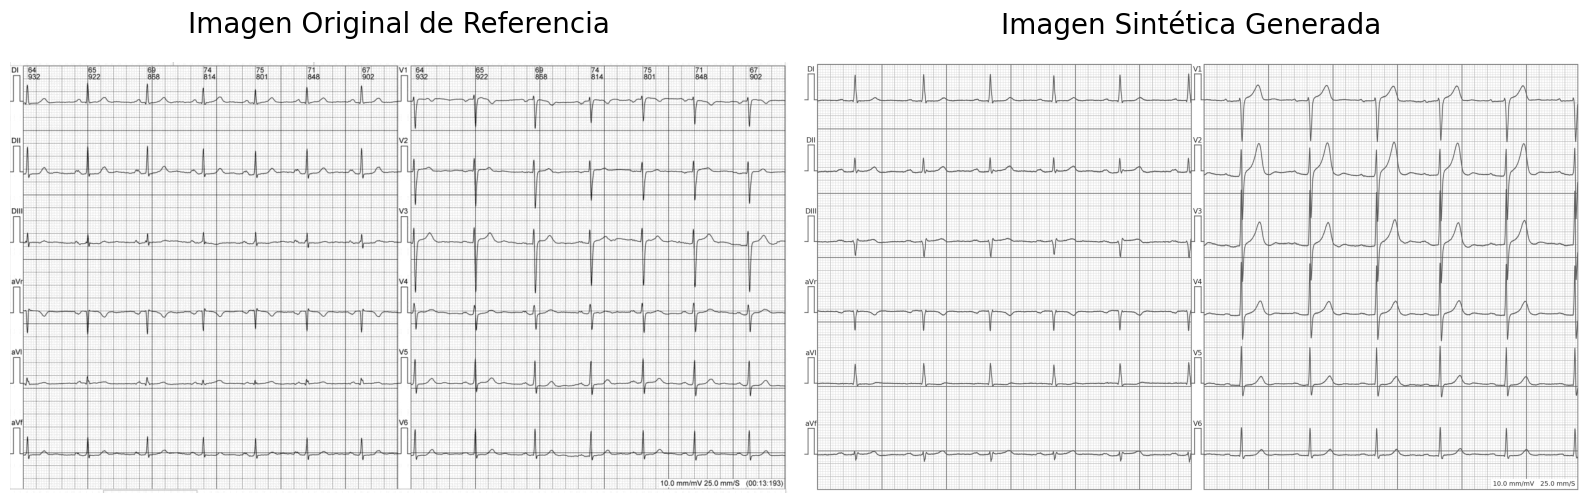

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(img_ref, cmap='gray')
axes[0].set_title("Imagen Original de Referencia", y=1.05, fontsize=20)
axes[0].axis("off")

axes[1].imshow(img_syn)
axes[1].set_title("Imagen Sintética Generada", y=1.05, fontsize=20)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# **GENERACIÓN DEL DATASET DE IMÁGENES SINTÉTICAS**

En esta segunda etapa, se define un pipeline de procesamiento en el cual la función **generate_image()**, definida previamente, se aplica de manera sistemática sobre todas las señales del dataset, permitiendo así convertir cada registro en su correspondiente representación en formato imagen.

**PARTICIÓN DEL DATASET**

Con el objetivo de garantizar reproducibilidad y evitar data leakage, la partición del dataset se realiza a nivel de señales antes de la generación de imágenes. De esta manera, todas las imágenes derivadas de una misma señal permanecen dentro del mismo subconjunto de datos. La función **create_splits()** realiza una división estratificada en conjuntos de entrenamiento (train) y prueba (test), considerando simultáneamente la clase diagnóstica (superclass) y el dataset de origen. Posteriormente, el subconjunto de entrenamiento se subdivide en 5 folds, permitiendo futuras etapas de entrenamiento con cross-validation. 

La estructura final del dataset generado es la siguiente:

In [ ]:
"""
output/
 ├── train/
 │    ├── fold_0/
 │    │    ├── NORM/
 │    │    ├── CD/
 │    │    ├── MI/
 │    │    ├── HYP/
 │    │    └── STTC/
 │    ├── fold_1/
 │    └── ...
 └── test/
      ├── NORM/
      ├── CD/
      ├── MI/
      ├── HYP/
      └── STTC/
"""

La función **save_splits()** ejecuta esta partición una única vez y almacena el resultado en un archivo CSV (splits.csv). Esto permite desacoplar la etapa de particionado de la generación de imágenes, posibilitando continuar el procesamiento en diferentes sesiones sin recalcular el split original.  Además, durante esta etapa se estima la cantidad de imágenes que generará cada señal. 

In [ ]:
# PARÁMETROS DE PARTICIÓN
TEST_SIZE        = 0.15
N_FOLDS          = 5
USE_SEGMENTATION = True

In [2]:
def create_splits(df, test_size=0.15, n_folds=5):

    df = df.copy()

    # Clave de estratificación
    df["stratify_key"] = df["superclass"] + "_" + df["dataset"]

    # TRAIN / TEST -------
    splitter = StratifiedShuffleSplit(
        n_splits=1,
        test_size=test_size,
        random_state=42
    )

    train_idx, test_idx = next(splitter.split(df, df["stratify_key"]))

    df_train = df.iloc[train_idx].reset_index(drop=True)
    df_test = df.iloc[test_idx].reset_index(drop=True)

    # FOLDS  ------
    skf = StratifiedKFold(
        n_splits=n_folds,
        shuffle=True,
        random_state=42
    )

    df_train["fold"] = -1

    for fold, (_, val_idx) in enumerate(
        skf.split(df_train, df_train["stratify_key"])
    ):
        df_train.loc[val_idx, "fold"] = fold + 1  

    return df_train, df_test

In [ ]:
def save_splits(
    csv_path,
    output_path,
    test_size=TEST_SIZE,
    n_folds=N_FOLDS,
    grid_big_boxes_w=29,
    time_scale_mm_s=25,
    max_overlap=0.30,
):

    df = pd.read_csv(csv_path)
    df_train, df_test = create_splits(df, test_size, n_folds)

    # Umbral de duración para generar 2 segmentos en vez de 1
    window_s    = (grid_big_boxes_w * 5) / time_scale_mm_s     # 5.8 s
    threshold_s = window_s * (2 - max_overlap)                 # 9.86 s

    # Detectar columnas de duración disponibles en el CSV
    samples_col  = next((c for c in df.columns if c in ("samples", "n_samples")), None)
    fs_col       = next((c for c in df.columns if c in ("fs", "sampling_frequency", "sampling_rate")), None)
    duration_col = next((c for c in df.columns if c in ("duration", "length_sec")), None)

    for split_df in (df_train, df_test):
        if samples_col and fs_col:
            split_df["n_segments"] = (
                (split_df[samples_col] / split_df[fs_col]) >= threshold_s
            ).astype(int) + 1
        elif duration_col:
            split_df["n_segments"] = (split_df[duration_col] >= threshold_s).astype(int) + 1
        else:
            split_df["n_segments"] = 1
            print("Aviso: no se encontró columna de duración en el CSV. n_segments=1 por defecto.")

    df_train["split"] = "train"
    df_test["split"]  = "test"
    df_test["fold"]   = 0      #

    os.makedirs(output_path, exist_ok=True)
    splits_path = os.path.join(output_path, "splits.csv")
    pd.concat([df_train, df_test], ignore_index=True).to_csv(splits_path, index=False)

    n_imgs_train = int(df_train["n_segments"].sum())
    n_imgs_test  = int(df_test["n_segments"].sum())

    print(f"Splits guardados en: {splits_path}")
    print(f"  Train: {len(df_train)} señales → {n_imgs_train} imágenes estimadas  (folds 1-{n_folds})")
    print(f"  Test:  {len(df_test)} señales  → {n_imgs_test} imágenes estimadas  (fold 0)")
    print(f"  Umbral 2 segmentos: {threshold_s:.2f} s")
    return splits_path

In [ ]:
# ── PASO 1 ─── Generar y guardar el split  ───────────────
save_splits(
    csv_path    = r"C:\Users\Victoria\Desktop\Datos Señales Filtered\Datos Señales Filtered.csv",
    output_path = r"C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas"
)

Splits guardados en: C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas\splits.csv
  Train: 29063 señales → 58121 imágenes estimadas  (folds 1-5)
  Test:  5129 señales  → 10258 imágenes estimadas  (fold 0)
  Umbral 2 segmentos: 9.86 s


'C:\\Users\\Victoria\\Desktop\\Datos Imágenes Sintéticas\\splits.csv'

**GENERACIÓN DE IMÁGENES**

Una vez definida la partición del dataset, la función **generate_image_dataset()** recorre secuencialmente cada señal perteneciente a los splits seleccionados y ejecuta el pipeline completo de generación de imágenes sintéticas.

El proceso completo se compone de las siguientes etapas:

1. **Lectura de señales**

    La función **load_ecg_signal()** se encarga de cargar las señales originales a partir de los archivos del dataset. Esta función recibe como entrada la ruta base del dataset, el nombre del archivo y su formato, utilizando la librería WFDB para acceder tanto a la señal como a su metadata asociada. La función devuelve la señal de ECG en formato matricial (N,12), la lista de nombres de derivaciones (lead_names) y la frecuencia de muestreo (fs) de la señal.

2. **Segmentación de señales**

    La función **split_signal()** permite generar más de una imagen a partir de una misma señal de ECG. Dado que muchos registros poseen una duración mayor que la ventana temporal representable en una única imagen, ciertas señales pueden dividirse en múltiples segmentos independientes. De este modo, es posible incrementar la cantidad de datos disponibles para el entrenamiento sin necesidad de incorporar nuevas señales. Con el objetivo de evitar redundancia excesiva, la segmentación solo se realiza cuando el solapamiento temporal entre ambos segmentos no supera el 30%. En señales de menor duración, únicamente se genera una imagen.

3. **Generación de imágenes**

    Cada segmento es procesado mediante la función **generate_image()**, encargada de renderizar la representación visual del ECG.
    Con el objetivo de introducir variabilidad visual y aproximar el comportamiento de adquisiciones reales, el margen lateral se mantiene fijo en 1 mm, mientras que el margen vertical se selecciona aleatoriamente dentro del intervalo [1.0 , 2.5] mm para cada imagen generada. Esta variabilidad produce pequeñas diferencias en el tamaño final de las imágenes, similares a las observadas al preprocesaro los datos reales del ICBA. Una vez renderizada, cada imagen se almacena automáticamente en la carpeta correspondiente a su split, fold y clase diagnóstica.




In [ ]:
# PARÁMETROS DE IMAGEN

# DPI fijo 
DPI  = 200
# Margen lateral fijo
MARGIN_X_MM     = 1.0   # mm
# Margen superior/inferior variable
MARGIN_Y_MIN_MM = 1.0   # mm
MARGIN_Y_MAX_MM = 2.5   # mm

In [17]:
def load_ecg_signal(base_path, filename, fmt):

    file_path = os.path.join(base_path, filename)
    record_name = os.path.splitext(file_path)[0]

    if fmt == "mat":
        # Leer con WFDB (usa .hea automáticamente)
        record = wfdb.rdrecord(record_name)
        ecg = record.p_signal          # (N, 12)
        fs = record.fs
        lead_names = record.sig_name
        del record

    elif fmt == "dat":
        record = wfdb.rdrecord(record_name)
        ecg = record.p_signal
        fs = record.fs
        lead_names = record.sig_name
        del record

    else:
        raise ValueError(f"Formato desconocido: {fmt}")

    return ecg, lead_names, fs

In [18]:
def split_signal(ecg, fs, grid_w_mm, time_scale_mm_s, use_segmentation=True, max_overlap=0.30):

    if not use_segmentation:
        return [ecg]

    N = ecg.shape[0]

    # Duración máxima que entra en la grilla
    window_seconds = grid_w_mm / time_scale_mm_s
    max_samples = int(window_seconds * fs)

    # Longitud mínima para que el solapamiento entre los dos segmentos no supere max_overlap
    # overlap = (2*window - signal_duration) / window  →  signal_duration >= window * (2 - max_overlap)
    min_samples_for_two = int(window_seconds * (2 - max_overlap) * fs)

    if N < min_samples_for_two:
        return [ecg]

    # Dos segmentos: inicio y fin de la señal
    seg1 = ecg[:max_samples]
    seg2 = ecg[-max_samples:]

    return [seg1, seg2]

Debido al gran volumen de señales procesadas, la generación del dataset incorpora un mecanismo de checkpointing para garantizar tolerancia a fallos y permitir la ejecución en múltiples sesiones. Tras procesar cada señal, se actualiza automáticamente un archivo CSV (datos_imagenes_sinteticas.csv) que almacena la metadata asociada a todas las imágenes generadas hasta el momento.
Antes de generar una nueva imagen, el pipeline verifica si la misma ya fue procesada previamente. En caso afirmativo, el registro se omite automáticamente.

In [19]:
def generate_image_dataset(
    signal_data_path,
    output_path,
    splits_csv=None,
    csv_path=None,
    folds_to_run=None,
    splits_to_run=("train", "test"),
    dpi=DPI,
    margin_x_mm=MARGIN_X_MM,
    margin_y_min_mm=MARGIN_Y_MIN_MM,
    margin_y_max_mm=MARGIN_Y_MAX_MM,
    use_segmentation=USE_SEGMENTATION,
    max_overlap=0.30,
    grid_big_boxes_w=29,
    time_scale_mm_s=25,
):
    from tqdm import tqdm

    grid_w_mm = grid_big_boxes_w * 5

    # ================================
    # CARGAR SPLITS
    # ================================
    if splits_csv is None:
        splits_csv = os.path.join(output_path, "splits.csv")

    if os.path.exists(splits_csv):
        df_all   = pd.read_csv(splits_csv)
        df_train = df_all[df_all["split"] == "train"].copy()
        df_test  = df_all[df_all["split"] == "test"].copy()
        print(f"Splits cargados desde: {splits_csv}")
    elif csv_path is not None:
        print("No se encontró splits.csv — generando split on-the-fly...")
        df       = pd.read_csv(csv_path)
        df_train, df_test = create_splits(df, TEST_SIZE, N_FOLDS)
    else:
        raise ValueError("Proveer splits_csv o csv_path.")

    if folds_to_run is not None and "train" in splits_to_run:
        df_train = df_train[df_train["fold"].isin(folds_to_run)].copy()
        print(f"Folds seleccionados: {folds_to_run}  ({len(df_train)} señales)")

    os.makedirs(output_path, exist_ok=True)
    checkpoint_path = os.path.join(output_path, "datos_imagenes_sinteticas.csv")

    # ================================
    # CHECKPOINT
    # ================================
    if os.path.exists(checkpoint_path):
        df_prev = pd.read_csv(checkpoint_path)
        records = df_prev.to_dict("records")
        processed_ids = set(df_prev["image_id"].tolist())
        print(f"Checkpoint: {len(records)} imágenes ya registradas.")
    else:
        records = []
        processed_ids = set()

    # ================================
    # PROCESAMIENTO
    # ================================
    def process_split(df_split, split_name):

        pbar = tqdm(df_split.iterrows(), total=len(df_split), desc=split_name.upper())

        for _, row in pbar:

            base_name = os.path.splitext(row["filename"])[0]

            # Early exit ANTES de cargar la señal:
            # si ambos segmentos posibles ya están procesados, saltar directo.
            # Para señales de 1 segmento, _1 nunca estará en processed_ids,
            # así que se cargan igual pero su único segmento se saltea adentro.
            if (f"{split_name}/{base_name}_0.jpg" in processed_ids and
                    f"{split_name}/{base_name}_1.jpg" in processed_ids):
                continue

            ecg, lead_names_sig, fs = load_ecg_signal(
                signal_data_path, row["filename"], row["format"]
            )

            segments = split_signal(ecg, fs, grid_w_mm, time_scale_mm_s, use_segmentation, max_overlap)
            del ecg

            for seg_idx, seg in enumerate(segments):

                img_name  = f"{base_name}_{seg_idx}.jpg"
                image_id  = f"{split_name}/{img_name}"
                fold      = int(row["fold"])

                if split_name == "train":
                    save_dir = os.path.join(output_path, "train", f"fold_{fold}", row["superclass"])
                else:
                    save_dir = os.path.join(output_path, "test", row["superclass"])

                os.makedirs(save_dir, exist_ok=True)
                save_path_img = os.path.join(save_dir, img_name)

                if image_id in processed_ids:
                    continue

                margin_y = random.uniform(margin_y_min_mm, margin_y_max_mm)

                generate_image(
                    seg.T,
                    lead_names_sig,
                    sampling_rate=fs,
                    dpi=dpi,
                    margin_x_mm=margin_x_mm,
                    margin_y_mm=margin_y,
                    save_path=save_path_img,
                )

                record = row.to_dict()
                for col in ("id", "filename", "format"):
                    record.pop(col, None)

                record.update({
                    "image_id":     image_id,
                    "image_format": "jpg",
                    "signal_id":    base_name,
                    "segment_id":   seg_idx,
                    "split":        split_name,
                    "fold":         fold,
                    "dpi":          dpi,
                    "margin_x_mm":  margin_x_mm,
                    "margin_y_mm":  round(margin_y, 2),
                })
                records.append(record)
                processed_ids.add(image_id)

            pd.DataFrame(records).to_csv(checkpoint_path, index=False)
            pbar.set_postfix({"imgs": len(records)})

        pbar.close()

    if "train" in splits_to_run:
        process_split(df_train, "train")
    if "test" in splits_to_run:
        process_split(df_test, "test")

    pd.DataFrame(records).to_csv(checkpoint_path, index=False)
    print(f"\nDataset generado: {len(records)} imágenes")
    print(f"Guardado en: {output_path}")

In [21]:
# ── PASO 2 ─── Generar imágenes (se puede correr por tramos) ──────────────────
generate_image_dataset(
    signal_data_path = r"C:\Users\Victoria\Desktop\Datos Señales Filtered",
    output_path      = r"C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas",
    folds_to_run     = None,               
    splits_to_run    = ("train", "test"),
)

Splits cargados desde: C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas\splits.csv
Checkpoint: 67751 imágenes ya registradas.


TEST: 100%|██████████| 5129/5129 [04:21<00:00, 19.64it/s, imgs=68379]   



Dataset generado: 68379 imágenes
Guardado en: C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas


Una vez finalizado el proceso de generación, a modo de verificación, se analizó la distribución de imágenes obtenida en cada subconjunto del dataset.

In [2]:
image_data_path = r"C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas\datos_imagenes_sinteticas.csv"
signal_data_path = r"C:\Users\Victoria\Desktop\Datos Señales Filtered\Datos Señales Filtered.csv"

df_img = pd.read_csv(image_data_path)
df_signal = pd.read_csv(signal_data_path)

class_order = ["NORM", "CD", "MI", "HYP", "STTC"]

for df_ in [df_img, df_signal]:

    df_["dataset"] = df_["dataset"].replace({
        "cpsc_2018": "cpsc",
        "cpsc_2018_extra": "cpsc"
    })

color_map = {
    "ptb-xl":           "#B11919",
    "georgia":          "#F16666",
    "cpsc":             "#0C4AA6",
    "chapman_shaoxing": "#8ECCFF",
}

common_cols = list(color_map.keys())
colors = [color_map[c] for c in common_cols]


def get_counts(df):

    counts = (
        df.groupby(["superclass", "dataset"])
          .size()
          .unstack(fill_value=0)
    )

    counts = counts.reindex(class_order)

    # asegurar columnas consistentes
    for col in common_cols:
        if col not in counts.columns:
            counts[col] = 0

    counts = counts[common_cols]

    return counts

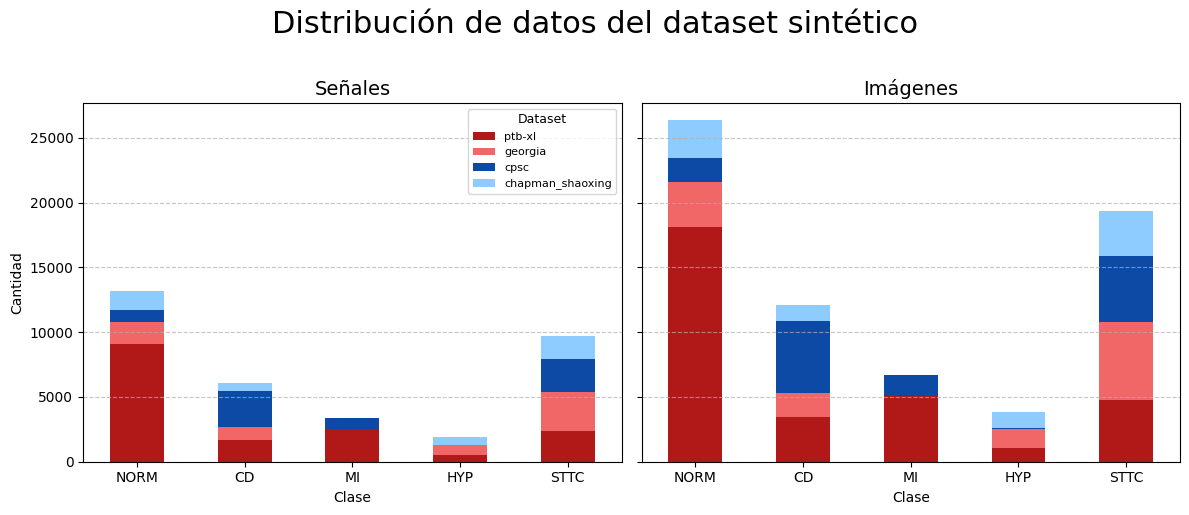

In [3]:
# DATASETS

df_train = df_img[df_img["split"] == "train"]
df_test  = df_img[df_img["split"] == "test"]

counts_signal = get_counts(df_signal)
counts_train  = get_counts(df_train)
counts_test   = get_counts(df_test)
counts_images = counts_train + counts_test


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

plots = [
    (counts_signal, "Señales"),
    (counts_images, "Imágenes"),
]

for ax, (counts, title) in zip(axes, plots):

    counts.plot(
        kind="bar",
        stacked=True,
        color=colors,
        ax=ax
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Clase")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=0)

axes[0].set_ylabel("Cantidad")

axes[1].get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(
    handles,
    labels,
    title="Dataset",
    fontsize=8,
    title_fontsize=9,
    loc="upper right"
)

plt.suptitle(
    "Distribución de datos del dataset sintético",
    fontsize=22,
    y=1.02
)

plt.tight_layout()
plt.show()

Puede observarse que las proporciones relativas entre clases y datasets se mantienen consistentes respecto a la distribución original de señales utilizada como entrada del pipeline. Esto indica que el proceso de partición estratificada y generación de imágenes preserva adecuadamente la composición del dataset de señales original. Asimismo, la estrategia de segmentación permitió incrementar (casi duplicar) la cantidad total de imágenes disponibles para entrenamiento sin alterar significativamente las proporciones globales entre clases.

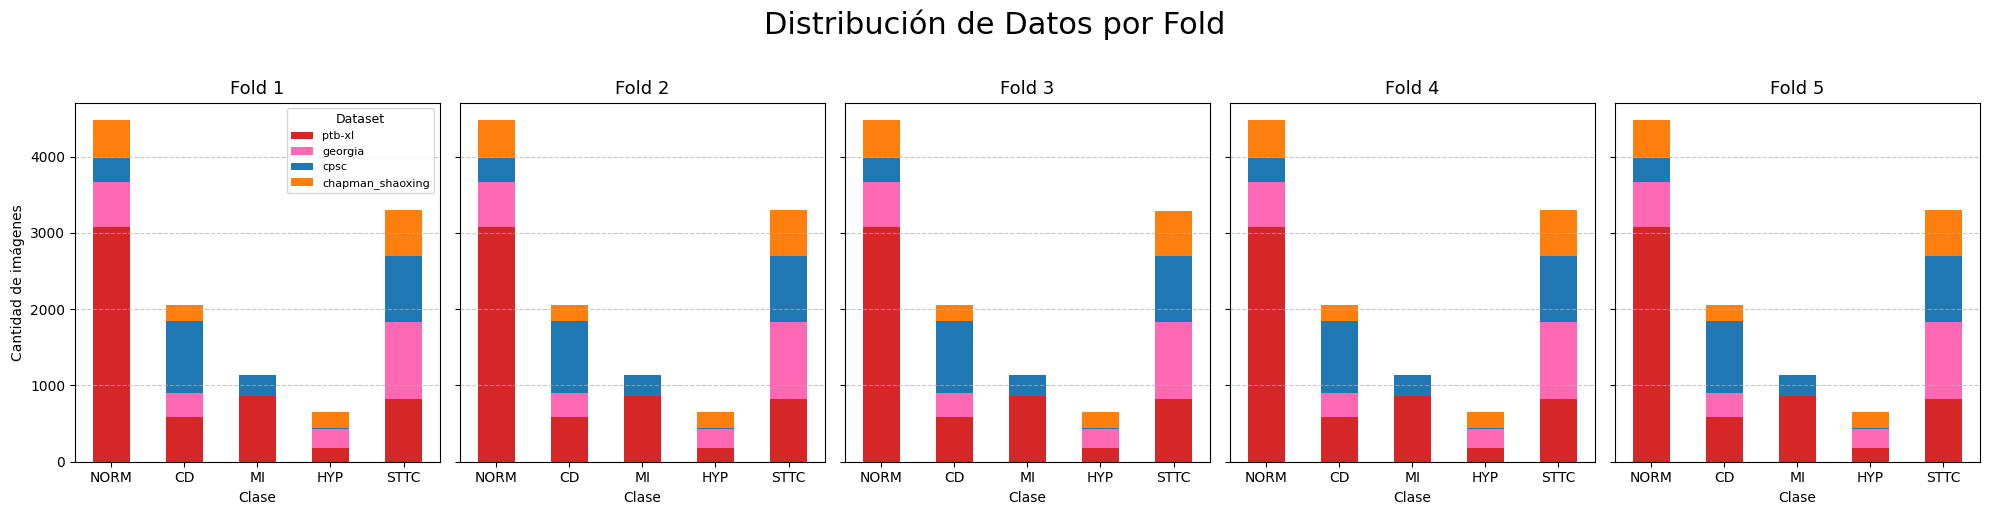

In [35]:
# DISTRIBUCIÓN POR FOLD

folds = sorted(df_train["fold"].unique())

fig, axes = plt.subplots(
    1,
    len(folds),
    figsize=(4 * len(folds), 5),
    sharey=True
)

if len(folds) == 1:
    axes = [axes]

for ax, fold in zip(axes, folds):

    subset = df_train[df_train["fold"] == fold]

    counts = get_counts(subset)

    counts.plot(
        kind="bar",
        stacked=True,
        color=colors,
        ax=ax
    )

    ax.set_title(f"Fold {fold}", fontsize=13)
    ax.set_xlabel("Clase")
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=0)

# ylabel solo primero
axes[0].set_ylabel("Cantidad de imágenes")

for ax in axes[1:]:
    ax.get_legend().remove()

# leyenda única
handles, labels = axes[0].get_legend_handles_labels()

axes[0].legend(
    handles,
    labels,
    title="Dataset",
    fontsize=8,
    title_fontsize=9,
    loc="upper right"
)

plt.suptitle(
    "Distribución de Datos por Fold",
    fontsize=22,
    y=1.02
)

plt.tight_layout()
plt.show()

Además, se verifica que la distribución entre los distintos folds se haya realizado correctamente, manteniendo en cada uno proporciones similares de clases diagnósticas y datasets de origen.

In [36]:
print("\n" + "="*60)
print("📊 DISTRIBUCIÓN DEL DATASET")
print("="*60)

for fold in sorted(df_train["fold"].unique()):

    print(f"\n🔹 FOLD {fold}")

    subset = df_train[df_train["fold"] == fold]

    counts = subset.groupby(["superclass", "dataset"]).size().unstack(fill_value=0)
    counts = counts.reindex(class_order)

    print(counts)



📊 DISTRIBUCIÓN DEL DATASET

🔹 FOLD 1
dataset     chapman_shaoxing  cpsc  georgia  ptb-xl
superclass                                         
NORM                     494   312      590    3084
CD                       214   944      320     580
MI                         4   276        0     862
HYP                      208     8      250     182
STTC                     596   866     1018     816

🔹 FOLD 2
dataset     chapman_shaoxing  cpsc  georgia  ptb-xl
superclass                                         
NORM                     496   312      590    3082
CD                       214   943      320     582
MI                         4   276        0     860
HYP                      208     8      250     182
STTC                     596   866     1018     816

🔹 FOLD 3
dataset     chapman_shaoxing  cpsc  georgia  ptb-xl
superclass                                         
NORM                     496   312      590    3084
CD                       214   944      320     582
MI    

**REDIMENSIONAMIENTO**

Las imágenes sintéticas generadas presentan dimensiones variables como consecuencia de la variabilidad de márgenes introducida durante el proceso de generación. Sin embargo, las redes neuronales convolucionales requieren que todas las imágenes de entrada tengan dimensiones fijas. Para satisfacer este requisito, todas las imágenes fueron redimensionadas a un tamaño uniforme de 352 × 192, consistente con el redimensionamiento aplicado a las imágenes del dataset del ICBA.

In [2]:
IMG_PATH  = r"C:\Users\Victoria\Desktop\Datos Imágenes Sintéticas"
IMG_RESIZED_PATH = r"C:\Users\Victoria\Desktop\Dataset Sintetico 352x192"
IMG_SIZE = (352, 192)
VAL_FOLD = 5

In [1]:
def resize_and_save(img_size, src_path, dst_path):
    if os.path.exists(dst_path):
        return 
    os.makedirs(os.path.dirname(dst_path), exist_ok=True)
    img = Image.open(src_path).convert("L")       # Convertir a escala de grises
    img = img.resize(img_size, Image.LANCZOS)     # Redimensionar con alta calidad
    img.save(dst_path, "JPEG", quality=95)

In [8]:
# ── TRAIN y VAL (desde folds) ────────────────────────────────────────────────
train_src = os.path.join(IMG_PATH, "train")

for fold_dir in sorted(os.listdir(train_src)):
    if not fold_dir.startswith("fold_"):
        continue
    fold_num   = int(fold_dir.replace("fold_", ""))
    split_name = "val" if fold_num == VAL_FOLD else "train"
    fold_path  = os.path.join(train_src, fold_dir)

    for class_name in sorted(os.listdir(fold_path)):
        class_path = os.path.join(fold_path, class_name)
        if not os.path.isdir(class_path):
            continue
        images = [f for f in os.listdir(class_path) if f.endswith(".jpg")]
        for img_file in tqdm(images, desc=f"{split_name}/{class_name} (fold {fold_num})"):
            src = os.path.join(class_path, img_file)
            dst = os.path.join(IMG_RESIZED_PATH, split_name, class_name, img_file)
            resize_and_save(IMG_SIZE, src, dst)

# ── TEST ─────────────────────────────────────────────────────────────────────
test_src = os.path.join(IMG_PATH, "test")

for class_name in sorted(os.listdir(test_src)):
    class_path = os.path.join(test_src, class_name)
    if not os.path.isdir(class_path):
        continue
    images = [f for f in os.listdir(class_path) if f.endswith(".jpg")]
    for img_file in tqdm(images, desc=f"test/{class_name}"):
        src = os.path.join(class_path, img_file)
        dst = os.path.join(IMG_RESIZED_PATH, "test", class_name, img_file)
        resize_and_save(IMG_SIZE, src, dst)

test/STTC: 100%|██████████| 2912/2912 [02:44<00:00, 17.73it/s]


In [10]:
# ── RESUMEN ───────────────────────────────────────────────────────────────────
print("\nEstructura generada:")

total_general = 0

for split in ("train", "val", "test"):
    split_path = os.path.join(IMG_RESIZED_PATH, split)
    if not os.path.isdir(split_path):
        continue

    total = sum(len(files) for _, _, files in os.walk(split_path))
    print(f"  {split}/  →  {total} imágenes")
    total_general += total

print(f"\nTOTAL GENERAL → {total_general} imágenes")


Estructura generada:
  train/  →  46497 imágenes
  val/  →  11624 imágenes
  test/  →  10258 imágenes

TOTAL GENERAL → 68379 imágenes


A continuación, a modo de ejemplo, se muestra una imagen síntetica redimensionada a su tamaño de entrada a la red.

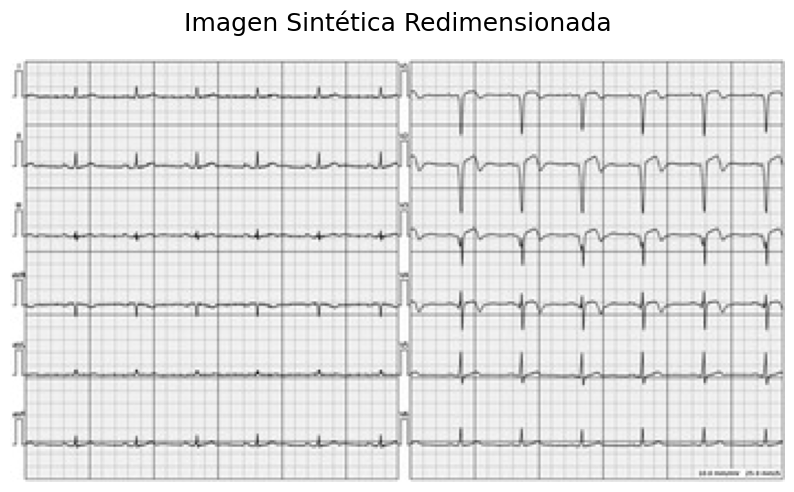

In [9]:
# Elegir split aleatorio
split = random.choice(["train", "val", "test"])
split_path = os.path.join(IMG_RESIZED_PATH, split)

# Elegir clase aleatoria
class_name = random.choice(os.listdir(split_path))
class_path = os.path.join(split_path, class_name)

# Elegir imagen aleatoria
img_name = random.choice(os.listdir(class_path))
img_path = os.path.join(class_path, img_name)

# Abrir imagen
img = Image.open(img_path)

# Mostrar
plt.figure(figsize=(10, 6))
plt.imshow(img, cmap="gray")
plt.title("Imagen Sintética Redimensionada", fontsize=18, y=1.05)
plt.axis("off")
plt.show()